# FMA Dataset: Basic Data Analysis

This notebook performs comprehensive exploratory data analysis (EDA) on the Free Music Archive (FMA) dataset.

## Analysis Overview:
1. Dataset Overview and Structure
2. Genre Distribution Analysis
3. Audio Features Statistical Analysis
4. Track Metadata Exploration
5. Data Quality Assessment
6. Visualizations and Insights

## 1. Setup and Data Loading

In [26]:
# Import required libraries
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

print('Libraries loaded successfully!')

Libraries loaded successfully!


In [27]:
# Define project paths
PROJECT_ROOT = Path(r'C:\HKBU_FYP')
AUDIO_ROOT = PROJECT_ROOT / 'dataset' / 'fma_small'
METADATA_ROOT = PROJECT_ROOT / 'dataset' / 'fma_metadata'
PROCESSED_ROOT = PROJECT_ROOT / 'processed'

# Define file paths
TRACKS_PATH = METADATA_ROOT / 'tracks.csv'
GENRES_PATH = METADATA_ROOT / 'genres.csv'
FEATURES_PATH = METADATA_ROOT / 'features.csv'

print('Project Configuration:')
print(f'Project Root: {PROJECT_ROOT}')
print(f'Audio Folder: {AUDIO_ROOT} (exists: {AUDIO_ROOT.exists()})')
print(f'Metadata Folder: {METADATA_ROOT} (exists: {METADATA_ROOT.exists()})')
print(f'\nMetadata Files:')
print(f'  - Tracks: {TRACKS_PATH.exists()}')
print(f'  - Genres: {GENRES_PATH.exists()}')
print(f'  - Features: {FEATURES_PATH.exists()}')

Project Configuration:
Project Root: C:\HKBU_FYP
Audio Folder: C:\HKBU_FYP\dataset\fma_small (exists: True)
Metadata Folder: C:\HKBU_FYP\dataset\fma_metadata (exists: True)

Metadata Files:
  - Tracks: True
  - Genres: True
  - Features: True


## 2. Load Dataset

In [28]:
# Load tracks metadata (multi-level columns)
tracks = pd.read_csv(TRACKS_PATH, index_col=0, header=[0, 1])

print('Tracks Metadata Loaded:')
print(f'Shape: {tracks.shape}')
print(f'\nColumn Groups: {tracks.columns.get_level_values(0).unique().tolist()}')
print(f'\nFirst few rows:')
display(tracks.head())

Tracks Metadata Loaded:
Shape: (106574, 52)

Column Groups: ['album', 'artist', 'set', 'track']

First few rows:


album                                                     \
         comments         date_created        date_released engineer   
track_id                                                               
2               0  2008-11-26 01:44:45  2009-01-05 00:00:00      NaN   
3               0  2008-11-26 01:44:45  2009-01-05 00:00:00      NaN   
5               0  2008-11-26 01:44:45  2009-01-05 00:00:00      NaN   
10              0  2008-11-26 01:45:08  2008-02-06 00:00:00      NaN   
20              0  2008-11-26 01:45:05  2009-01-06 00:00:00      NaN   

                                                                          \
         favorites id                                information listens   
track_id                                                                   
2                4  1                                    <p></p>    6073   
3                4  1                                    <p></p>    6073   
5                4  1                                    <p></p>    6073   
10               4  6                                        NaN   47632   
20               2  4  <p> "spiritual songs" from Nicky Cook</p>    2710   

                        ...       track                         \
         producer tags  ... information interest language_code   
track_id                ...                                      
2             NaN   []  ...         NaN     4656            en   
3             NaN   []  ...         NaN     1470            en   
5             NaN   []  ...         NaN     1933            en   
10            NaN   []  ...         NaN    54881            en   
20            NaN   []  ...         NaN      978            en   

                                                                              \
                                                    license listens lyricist   
track_id                                                                       
2         Attribution-NonCommercial-ShareAlike 3.0 Inter...    1293      NaN   
3         Attribution-NonCommercial-ShareAlike 3.0 Inter...     514      NaN   
5         Attribution-NonCommercial-ShareAlike 3.0 Inter...    1151      NaN   
10        Attribution-NonCommercial-NoDerivatives (aka M...   50135      NaN   
20        Attribution-NonCommercial-NoDerivatives (aka M...     361      NaN   

                                                 
         number publisher tags            title  
track_id                                         
2             3       NaN   []             Food  
3             4       NaN   []     Electric Ave  
5             6       NaN   []       This World  
10            1       NaN   []          Freeway  
20            3       NaN   []  Spiritual Level  

[5 rows x 52 columns]

In [29]:
# Load genres metadata
genres = pd.read_csv(GENRES_PATH)

print('Genres Metadata Loaded:')
print(f'Shape: {genres.shape}')
print(f'Columns: {genres.columns.tolist()}')
print(f'\nSample:')
display(genres.head(10))

Genres Metadata Loaded:
Shape: (163, 5)
Columns: ['genre_id', '#tracks', 'parent', 'title', 'top_level']

Sample:


,genre_id,#tracks,parent,title,top_level
0,1,8693,38,Avant-Garde,38
1,2,5271,0,International,2
2,3,1752,0,Blues,3
3,4,4126,0,Jazz,4
4,5,4106,0,Classical,5
5,6,914,38,Novelty,38
6,7,217,20,Comedy,20
7,8,868,0,Old-Time / Historic,8
8,9,1987,0,Country,9
9,10,13845,0,Pop,10


In [30]:
# Count audio files
audio_files = sorted(AUDIO_ROOT.rglob('*.mp3'))
print(f'Total MP3 files found: {len(audio_files)}')

# Show sample paths
print(f'\nSample audio file paths:')
for path in audio_files[:5]:
    print(f'  - {path}')

Total MP3 files found: 8000

Sample audio file paths:
  - C:\HKBU_FYP\dataset\fma_small\000\000002.mp3
  - C:\HKBU_FYP\dataset\fma_small\000\000005.mp3
  - C:\HKBU_FYP\dataset\fma_small\000\000010.mp3
  - C:\HKBU_FYP\dataset\fma_small\000\000140.mp3
  - C:\HKBU_FYP\dataset\fma_small\000\000141.mp3


## 3. Dataset Overview and Structure

In [31]:
# Detailed column information
print('Track Metadata Column Structure:\n')
for group in tracks.columns.get_level_values(0).unique():
    cols = tracks[group].columns.tolist()
    print(f'{group.upper()} ({len(cols)} columns):')
    for i, col in enumerate(cols, 1):
        print(f'  {i}. {col}')
    print()

Track Metadata Column Structure:

ALBUM (13 columns):
  1. comments
  2. date_created
  3. date_released
  4. engineer
  5. favorites
  6. id
  7. information
  8. listens
  9. producer
  10. tags
  11. title
  12. tracks
  13. type

ARTIST (17 columns):
  1. active_year_begin
  2. active_year_end
  3. associated_labels
  4. bio
  5. comments
  6. date_created
  7. favorites
  8. id
  9. latitude
  10. location
  11. longitude
  12. members
  13. name
  14. related_projects
  15. tags
  16. website
  17. wikipedia_page

SET (2 columns):
  1. split
  2. subset

TRACK (20 columns):
  1. bit_rate
  2. comments
  3. composer
  4. date_created
  5. date_recorded
  6. duration
  7. favorites
  8. genre_top
  9. genres
  10. genres_all
  11. information
  12. interest
  13. language_code
  14. license
  15. listens
  16. lyricist
  17. number
  18. publisher
  19. tags
  20. title



In [32]:
# Basic statistics
print('Dataset Statistics:\n')
print(f'Total tracks in metadata: {len(tracks):,}')
print(f'Total audio files available: {len(audio_files):,}')
print(f'Unique genres (top-level): {genres["top_level"].nunique()}')
print(f'Total genre categories: {len(genres)}')

# Missing data analysis
print(f'\nMissing Audio Files:')
print(f'{len(tracks) - len(audio_files):,} tracks have metadata but no audio file')

Dataset Statistics:

Total tracks in metadata: 106,574
Total audio files available: 8,000
Unique genres (top-level): 16
Total genre categories: 163

Missing Audio Files:
98,574 tracks have metadata but no audio file


## 4. Genre Distribution Analysis

In [33]:
# Genre distribution from tracks
genre_column = ('track', 'genre_top')
genre_counts = tracks[genre_column].fillna('Unknown').value_counts()

print('Top-Level Genre Distribution:\n')
genre_df = pd.DataFrame({
    'Genre': genre_counts.index,
    'Count': genre_counts.values,
    'Percentage': (genre_counts.values / len(tracks) * 100).round(2)
}).reset_index(drop=True)

display(genre_df)

Top-Level Genre Distribution:



,Genre,Count,Percentage
0,Unknown,56976,53.46
1,Rock,14182,13.31
2,Experimental,10608,9.95
3,Electronic,9372,8.79
4,Hip-Hop,3552,3.33
5,Folk,2803,2.63
6,Pop,2332,2.19
7,Instrumental,2079,1.95
8,International,1389,1.30
9,Classical,1230,1.15


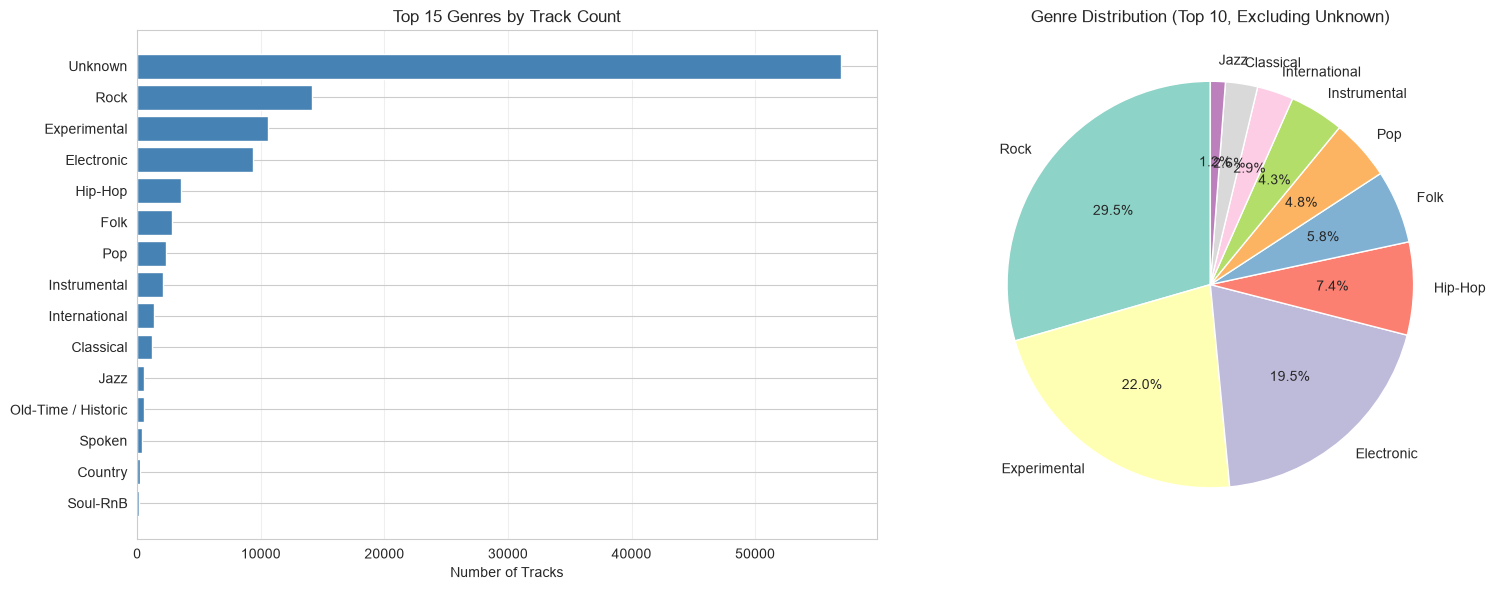

Total known genres (excluding Unknown): 49,598


In [34]:
# Visualize genre distribution (top 15)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Bar plot
top_genres = genre_df.head(15)
axes[0].barh(range(len(top_genres)), top_genres['Count'], color='steelblue')
axes[0].set_yticks(range(len(top_genres)))
axes[0].set_yticklabels(top_genres['Genre'])
axes[0].set_xlabel('Number of Tracks')
axes[0].set_title('Top 15 Genres by Track Count')
axes[0].invert_yaxis()
axes[0].grid(axis='x', alpha=0.3)

# Pie chart (excluding Unknown)
known_genres = genre_df[genre_df['Genre'] != 'Unknown'].head(10)
colors = plt.cm.Set3(range(len(known_genres)))
axes[1].pie(known_genres['Count'], labels=known_genres['Genre'], 
            autopct='%1.1f%%', startangle=90, colors=colors)
axes[1].set_title('Genre Distribution (Top 10, Excluding Unknown)')

plt.tight_layout()
plt.show()

print(f'Total known genres (excluding Unknown): {genre_df[genre_df["Genre"] != "Unknown"]["Count"].sum():,}')

## 5. Track Metadata Analysis

In [35]:
# Track duration analysis
duration_col = ('track', 'duration')
durations = tracks[duration_col].dropna()

print('Track Duration Statistics:\n')
print(f'Total tracks with duration data: {len(durations):,}')
print(f'Mean duration: {durations.mean():.2f} seconds ({durations.mean()/60:.2f} minutes)')
print(f'Median duration: {durations.median():.2f} seconds')
print(f'Min duration: {durations.min():.2f} seconds')
print(f'Max duration: {durations.max():.2f} seconds')
print(f'Std deviation: {durations.std():.2f} seconds')

Track Duration Statistics:

Total tracks with duration data: 106,574
Mean duration: 277.85 seconds (4.63 minutes)
Median duration: 216.00 seconds
Min duration: 0.00 seconds
Max duration: 18350.00 seconds
Std deviation: 305.52 seconds


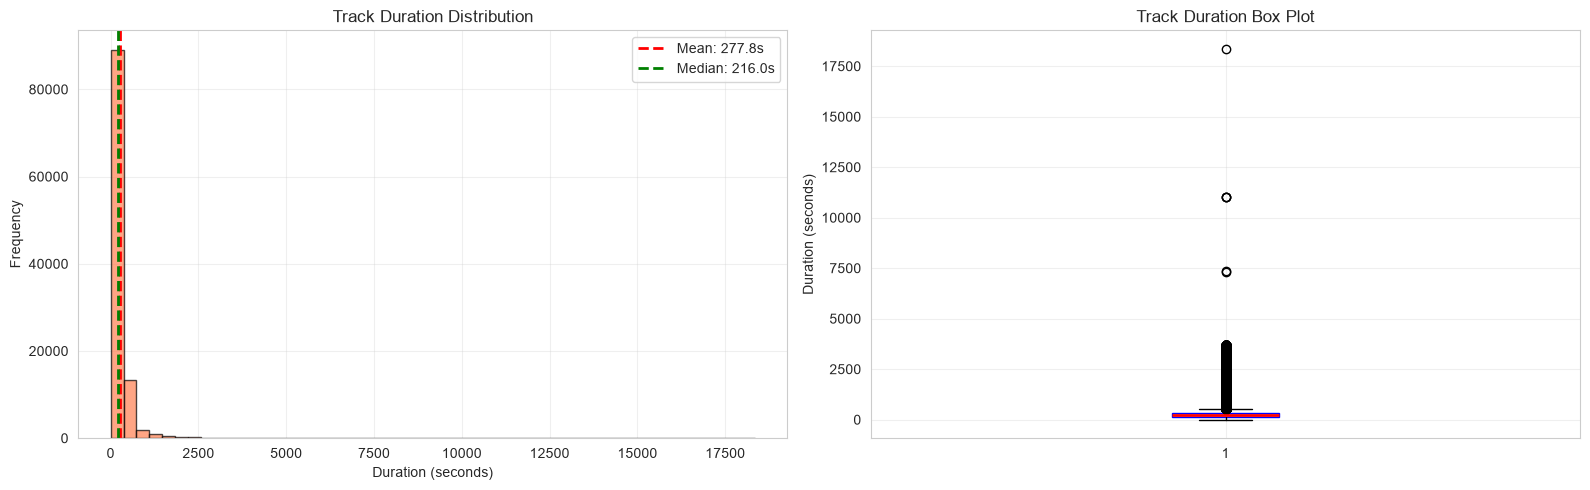

In [36]:
# Visualize duration distribution
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Histogram
axes[0].hist(durations, bins=50, color='coral', edgecolor='black', alpha=0.7)
axes[0].axvline(durations.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {durations.mean():.1f}s')
axes[0].axvline(durations.median(), color='green', linestyle='--', linewidth=2, label=f'Median: {durations.median():.1f}s')
axes[0].set_xlabel('Duration (seconds)')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Track Duration Distribution')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Box plot
axes[1].boxplot(durations, vert=True, patch_artist=True,
                boxprops=dict(facecolor='lightblue', color='blue'),
                medianprops=dict(color='red', linewidth=2))
axes[1].set_ylabel('Duration (seconds)')
axes[1].set_title('Track Duration Box Plot')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [37]:
# Track interest and listens analysis
interest_col = ('track', 'interest')
listens_col = ('track', 'listens')

interest = tracks[interest_col].dropna()
listens = tracks[listens_col].dropna()

print('Track Engagement Statistics:\n')
print('INTEREST:')
print(f'  Tracks with interest data: {len(interest):,}')
print(f'  Mean interest: {interest.mean():.2f}')
print(f'  Median interest: {interest.median():.2f}')
print(f'  Max interest: {interest.max():.2f}')

print('\nLISTENS:')
print(f'  Tracks with listen data: {len(listens):,}')
print(f'  Total listens: {listens.sum():,}')
print(f'  Mean listens: {listens.mean():.2f}')
print(f'  Median listens: {listens.median():.2f}')
print(f'  Max listens: {listens.max():,}')

Track Engagement Statistics:

INTEREST:
  Tracks with interest data: 106,574
  Mean interest: 3541.31
  Median interest: 1314.00
  Max interest: 3293557.00

LISTENS:
  Tracks with listen data: 106,574
  Total listens: 248,248,525
  Mean listens: 2329.35
  Median listens: 764.00
  Max listens: 543,252


In [38]:
# Top listened tracks
top_tracks = tracks.nlargest(10, listens_col)[[('track', 'title'), ('artist', 'name'), listens_col, genre_column]]
top_tracks.columns = ['Title', 'Artist', 'Listens', 'Genre']

print('Top 10 Most Listened Tracks:\n')
display(top_tracks.reset_index())

Top 10 Most Listened Tracks:



,track_id,Title,Artist,Listens,Genre
0,42377,Night Owl,Broke For Free,543252,Electronic
1,81466,Starling,Podington Bear,491235,NaN
2,66053,Springish,Gillicuddy,468163,NaN
3,24425,Fater Lee,Black Ant,433992,Hip-Hop
4,86599,Epic Song,BoxCat Games,429168,NaN
5,96534,O Tannenbaum,Dan Lerch,400404,NaN
6,84990,Hachiko (The Faithtful Dog),The Kyoto Connection,374497,NaN
7,62460,Siesta,Jahzzar,356588,NaN
8,74724,It's Your Birthday!,Monk Turner + Fascinoma,349903,NaN
9,69170,Enthusiast,Tours,335215,Electronic


## 6. Artist Analysis

In [39]:
# Artist statistics
artist_col = ('artist', 'name')
artist_counts = tracks[artist_col].value_counts()

print('Artist Statistics:\n')
print(f'Total unique artists: {len(artist_counts):,}')
print(f'Average tracks per artist: {artist_counts.mean():.2f}')
print(f'Median tracks per artist: {artist_counts.median():.0f}')
print(f'Most prolific artist: {artist_counts.index[0]} ({artist_counts.iloc[0]} tracks)')

print('\nTop 15 Artists by Track Count:\n')
top_artists = pd.DataFrame({
    'Artist': artist_counts.head(15).index,
    'Track Count': artist_counts.head(15).values
}).reset_index(drop=True)
display(top_artists)

Artist Statistics:

Total unique artists: 16,294
Average tracks per artist: 6.54
Median tracks per artist: 2
Most prolific artist: Kosta T (745 tracks)

Top 15 Artists by Track Count:



,Artist,Track Count
0,Kosta T,745
1,Podington Bear,604
2,Ergo Phizmiz,499
3,Blue Dot Sessions,416
4,Lee Rosevere,371
5,Mr. & Mrs. Smith,353
6,Ars Sonor,333
7,Jahzzar,330
8,James Kibbie,319
9,Derek Clegg,316


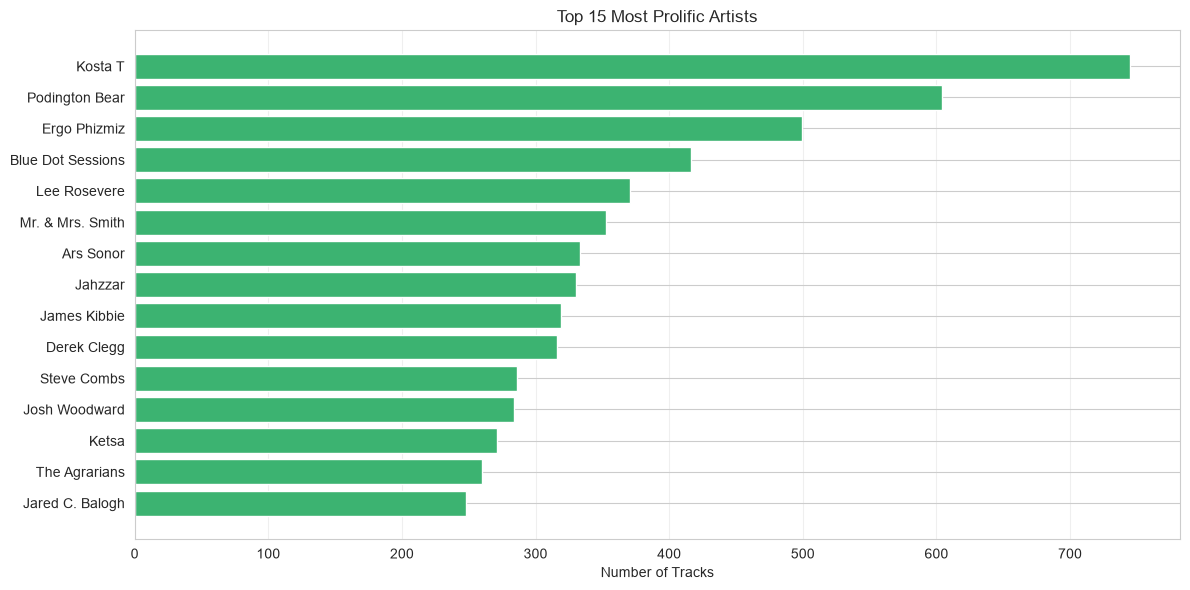

In [40]:
# Visualize top artists
fig, ax = plt.subplots(figsize=(12, 6))
top_15 = artist_counts.head(15)
ax.barh(range(len(top_15)), top_15.values, color='mediumseagreen')
ax.set_yticks(range(len(top_15)))
ax.set_yticklabels(top_15.index)
ax.set_xlabel('Number of Tracks')
ax.set_title('Top 15 Most Prolific Artists')
ax.invert_yaxis()
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Genre Hierarchy Analysis

In [41]:
# Top-level genre mapping
print('Genre Hierarchy Overview:\n')

# Get top-level genres
top_level_genres = genres[genres['parent'] == 0]
print(f'Total top-level genres: {len(top_level_genres)}')
print(f'\nTop-level genres:')
display(top_level_genres[['genre_id', 'title', '#tracks']].sort_values('#tracks', ascending=False))

# Count subgenres
total_subgenres = len(genres[genres['parent'] != 0])
print(f'\nTotal subgenres: {total_subgenres}')

Genre Hierarchy Overview:

Total top-level genres: 16

Top-level genres:


,genre_id,title,#tracks
31,38,Experimental,38154
14,15,Electronic,34413
11,12,Rock,32923
162,1235,Instrumental,14938
9,10,Pop,13845
16,17,Folk,12706
20,21,Hip-Hop,8389
1,2,International,5271
3,4,Jazz,4126
4,5,Classical,4106



Total subgenres: 147


In [42]:
# Genre tree depth analysis
genre_with_most_subgenres = genres.groupby('parent').size().sort_values(ascending=False).head(10)

print('Genres with Most Subgenres:\n')
for parent_id, count in genre_with_most_subgenres.items():
    if parent_id != 0:
        parent_genre = genres[genres['genre_id'] == parent_id]['title'].values
        if len(parent_genre) > 0:
            print(f'{parent_genre[0]}: {count} subgenres')

Genres with Most Subgenres:

International: 15 subgenres
Rock: 15 subgenres
Electronic: 14 subgenres
Experimental: 14 subgenres
Spoken: 8 subgenres
Classical: 7 subgenres
Hip-Hop: 7 subgenres
Jazz: 6 subgenres
Punk: 5 subgenres


## 8. Data Quality Assessment

In [43]:
# Missing data analysis for key columns
print('Missing Data Analysis:\n')

key_columns = [
    ('track', 'title'),
    ('track', 'genre_top'),
    ('track', 'duration'),
    ('track', 'listens'),
    ('track', 'interest'),
    ('artist', 'name'),
    ('artist', 'location')
]

missing_data = []
for col in key_columns:
    if col in tracks.columns:
        missing_count = tracks[col].isna().sum()
        missing_pct = (missing_count / len(tracks)) * 100
        missing_data.append({
            'Column': f'{col[0]}.{col[1]}',
            'Missing Count': missing_count,
            'Missing %': f'{missing_pct:.2f}%'
        })

missing_df = pd.DataFrame(missing_data)
display(missing_df)

Missing Data Analysis:



,Column,Missing Count,Missing %
0,track.title,1,0.00%
1,track.genre_top,56976,53.46%
2,track.duration,0,0.00%
3,track.listens,0,0.00%
4,track.interest,0,0.00%
5,artist.name,0,0.00%
6,artist.location,36364,34.12%


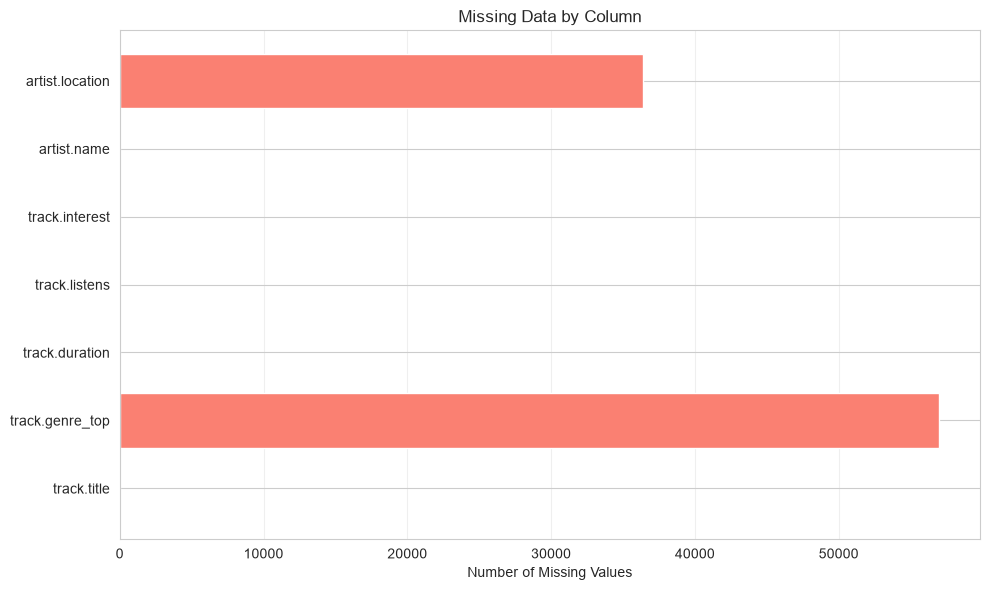

In [44]:
# Visualize missing data
fig, ax = plt.subplots(figsize=(10, 6))
missing_df['Missing Count'] = pd.to_numeric(missing_df['Missing Count'])
ax.barh(missing_df['Column'], missing_df['Missing Count'], color='salmon')
ax.set_xlabel('Number of Missing Values')
ax.set_title('Missing Data by Column')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

In [45]:
# Check for duplicate tracks
title_col = ('track', 'title')
duplicates = tracks[tracks.duplicated(subset=[title_col], keep=False)]

print(f'Data Quality Checks:\n')
print(f'Total duplicate titles: {len(duplicates):,}')
print(f'Unique duplicate titles: {duplicates[title_col].nunique():,}')

if len(duplicates) > 0:
    print(f'\nSample duplicate titles:')
    sample_dups = duplicates[title_col].value_counts().head(5)
    for title, count in sample_dups.items():
        print(f'  "{title}": {count} tracks')

Data Quality Checks:

Total duplicate titles: 17,860
Unique duplicate titles: 6,273

Sample duplicate titles:
  "Untitled": 298 tracks
  "Into Infinity "ear" loop": 150 tracks
  "Intro": 115 tracks
  "Interview": 92 tracks
  "Chicken and Cheese 2 (Foot Village cover)": 49 tracks


## 9. FMA-Small Subset Analysis

In [46]:
# Create mapping for available audio files
def get_track_id_from_path(path):
    """Extract track ID from audio file path"""
    return int(path.stem)

available_track_ids = [get_track_id_from_path(p) for p in audio_files]
print(f'Audio files available: {len(available_track_ids):,}')

# Filter tracks to only those with audio
fma_small = tracks.loc[tracks.index.isin(available_track_ids)].copy()
print(f'Tracks in FMA-small subset: {len(fma_small):,}')

Audio files available: 8,000
Tracks in FMA-small subset: 8,000


In [47]:
# Genre distribution in FMA-small
small_genre_counts = fma_small[genre_column].fillna('Unknown').value_counts()

print('Genre Distribution in FMA-Small:\n')
small_genre_df = pd.DataFrame({
    'Genre': small_genre_counts.index,
    'Count': small_genre_counts.values,
    'Percentage': (small_genre_counts.values / len(fma_small) * 100).round(2)
}).reset_index(drop=True)

display(small_genre_df)

Genre Distribution in FMA-Small:



,Genre,Count,Percentage
0,Hip-Hop,1000,12.5
1,Pop,1000,12.5
2,Folk,1000,12.5
3,Experimental,1000,12.5
4,Rock,1000,12.5
5,International,1000,12.5
6,Electronic,1000,12.5
7,Instrumental,1000,12.5


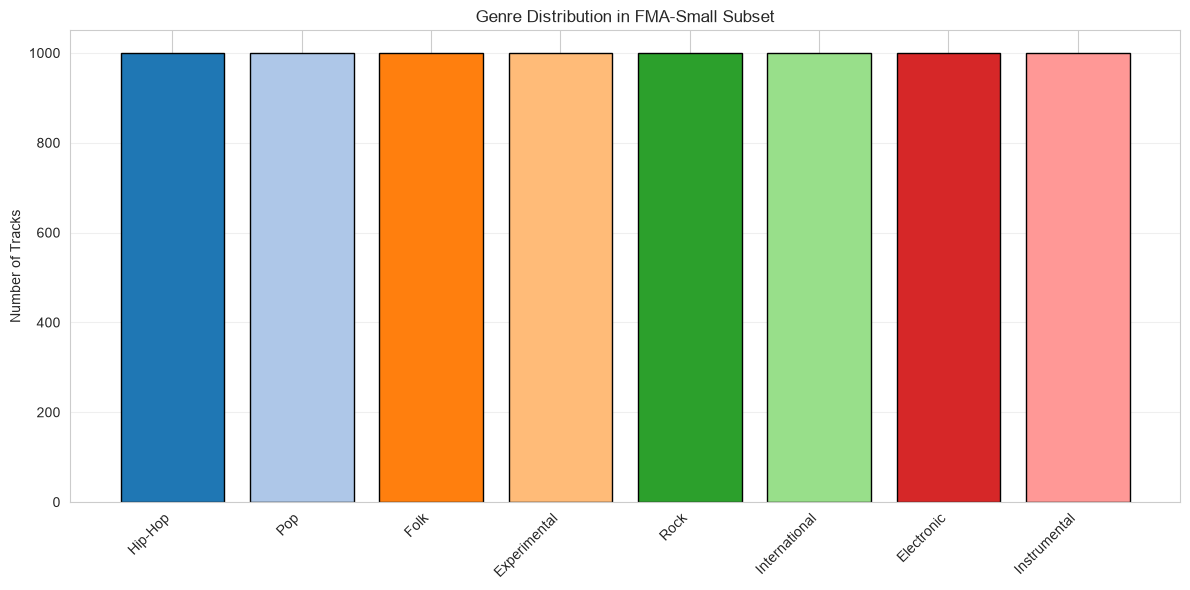


FMA-small contains 8 genres (excluding Unknown)


In [48]:
# Visualize FMA-small genre distribution
fig, ax = plt.subplots(figsize=(12, 6))
known_small = small_genre_df[small_genre_df['Genre'] != 'Unknown']
colors = plt.cm.tab20(range(len(known_small)))
ax.bar(range(len(known_small)), known_small['Count'], color=colors, edgecolor='black')
ax.set_xticks(range(len(known_small)))
ax.set_xticklabels(known_small['Genre'], rotation=45, ha='right')
ax.set_ylabel('Number of Tracks')
ax.set_title('Genre Distribution in FMA-Small Subset')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print(f'\nFMA-small contains {len(known_small)} genres (excluding Unknown)')

## 10. Summary and Key Insights

In [49]:
print('='*60)
print('FMA DATASET ANALYSIS SUMMARY')
print('='*60)

print('\n1. DATASET SIZE:')
print(f'   - Total tracks in metadata: {len(tracks):,}')
print(f'   - Audio files available (FMA-small): {len(audio_files):,}')
print(f'   - Data availability: {(len(audio_files)/len(tracks)*100):.2f}%')

print('\n2. GENRE DIVERSITY:')
print(f'   - Top-level genres: {genres["top_level"].nunique()}')
print(f'   - Total genre categories: {len(genres)}')
print(f'   - Most common genre: {genre_df.iloc[1]["Genre"]} ({genre_df.iloc[1]["Count"]:,} tracks)')

print('\n3. TRACK CHARACTERISTICS:')
print(f'   - Average duration: {durations.mean():.1f} seconds ({durations.mean()/60:.2f} minutes)')
print(f'   - Total listening time: {(durations.sum()/3600):.2f} hours')

print('\n4. ARTIST DIVERSITY:')
print(f'   - Unique artists: {len(artist_counts):,}')
print(f'   - Average tracks per artist: {artist_counts.mean():.2f}')

print('\n5. DATA QUALITY:')
print(f'   - Tracks with genre labels: {len(tracks[tracks[genre_column].notna()]):,}')
print(f'   - Tracks with duration data: {len(durations):,}')
print(f'   - Genre label coverage: {(len(tracks[tracks[genre_column].notna()])/len(tracks)*100):.2f}%')

print('\n' + '='*60)
print('ANALYSIS COMPLETE')
print('='*60)

FMA DATASET ANALYSIS SUMMARY

1. DATASET SIZE:
   - Total tracks in metadata: 106,574
   - Audio files available (FMA-small): 8,000
   - Data availability: 7.51%

2. GENRE DIVERSITY:
   - Top-level genres: 16
   - Total genre categories: 163
   - Most common genre: Rock (14,182 tracks)

3. TRACK CHARACTERISTICS:
   - Average duration: 277.8 seconds (4.63 minutes)
   - Total listening time: 8225.41 hours

4. ARTIST DIVERSITY:
   - Unique artists: 16,294
   - Average tracks per artist: 6.54

5. DATA QUALITY:
   - Tracks with genre labels: 49,598
   - Tracks with duration data: 106,574
   - Genre label coverage: 46.54%

ANALYSIS COMPLETE


## 11. Export Processed Data

In [ ]:
# Export FMA-small metadata with genre info
def get_audio_path(track_id):
    """Generate audio path for a track ID"""
    track_id = int(track_id)
    folder = f'{track_id // 1000:03d}'
    filename = f'{track_id:06d}.mp3'
    return AUDIO_ROOT / folder / filename

# Create cleaned dataset
export_data = []
for track_id in available_track_ids:
    if track_id in fma_small.index:
        row = fma_small.loc[track_id]
        export_data.append({
            'track_id': track_id,
            'title': row.get(('track', 'title'), 'Unknown'),
            'artist': row.get(('artist', 'name'), 'Unknown'),
            'genre': row.get(('track', 'genre_top'), 'Unknown'),
            'duration': row.get(('track', 'duration'), 0),
            'listens': row.get(('track', 'listens'), 0),
            'interest': row.get(('track', 'interest'), 0),
            'audio_path': str(get_audio_path(track_id))
        })

export_df = pd.DataFrame(export_data)
output_path = PROCESSED_ROOT / 'fma_small_analysis.csv'
export_df.to_csv(output_path, index=False)

print(f'Exported FMA-small analysis data:')
print(f'  Path: {output_path}')
print(f'  Rows: {len(export_df):}')
print(f'  Columns: {list(export_df.columns)}')
print(f'\nSample:')
display(export_df.head())

Exported FMA-small analysis data:
  Path: C:\HKBU_FYP\processed\fma_small_analysis.csv
  Rows: 8,000
  Columns: ['track_id', 'title', 'artist', 'genre', 'duration', 'listens', 'interest', 'audio_path']

Sample:


,track_id,title,artist,genre,duration,listens,interest,audio_path
0,2,Food,AWOL,Hip-Hop,168,1293,4656,C:\HKBU_FYP\dataset\fma_small\000\000002.mp3
1,5,This World,AWOL,Hip-Hop,206,1151,1933,C:\HKBU_FYP\dataset\fma_small\000\000005.mp3
2,10,Freeway,Kurt Vile,Pop,161,50135,54881,C:\HKBU_FYP\dataset\fma_small\000\000010.mp3
3,140,Queen Of The Wires,Alec K. Redfearn & the Eyesores,Folk,253,1299,1593,C:\HKBU_FYP\dataset\fma_small\000\000140.mp3
4,141,Ohio,Alec K. Redfearn & the Eyesores,Folk,182,725,839,C:\HKBU_FYP\dataset\fma_small\000\000141.mp3




This notebook provided a comprehensive overview of the FMA dataset including:
- Dataset structure and composition
- Genre distribution and diversity
- Track and artist statistics
- Data quality assessment
- FMA-small subset analysis

The processed data has been exported for use in downstream tasks like feature extraction and music recommendation.